# Outfit_Vision_Process

Environment Setup & Drive File Ingestion

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
import cv2
import numpy as np
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Function to search and load image from Drive
def load_image_from_drive(filename):
    image_path = None
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if filename in files:
            image_path = os.path.join(root, filename)
            break

    if image_path is None:
        raise FileNotFoundError(f"❌ Could not find '{filename}' in Google Drive. Please verify the filename and folder.")

    print(f"✅ Found and loaded: {image_path}")
    img_bgr = cv2.imread(image_path)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 3. Load your 4 specific files
target_outfit = load_image_from_drive('full outfit.webp')
user_shirt = load_image_from_drive('shirt.webp')
user_jeans = load_image_from_drive('jeans.webp')
user_jacket = load_image_from_drive('jacket.jpg')

print("\nCell 1 Complete: All 4 images successfully loaded from Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Found and loaded: /content/drive/MyDrive/New folder (1)/full outfit.webp
✅ Found and loaded: /content/drive/MyDrive/New folder (1)/shirt.webp
✅ Found and loaded: /content/drive/MyDrive/New folder (1)/jeans.webp
✅ Found and loaded: /content/drive/MyDrive/New folder (1)/jacket.jpg

Cell 1 Complete: All 4 images successfully loaded from Google Drive!


Preprocessing & Noise Reduction Pipeline







In [ ]:
import math

def preprocess_and_filter(image, target_size=(500, 500)):
    # Resize
    resized = cv2.resize(image, target_size)
    # Gaussian Filter (5x5 kernel)
    gauss = cv2.GaussianBlur(resized, (5, 5), 0)
    # Median Filter (5x5 kernel)
    median = cv2.medianBlur(resized, 5)
    return resized, gauss, median

def calculate_psnr(original, filtered):
    mse = np.mean((original.astype(np.float64) - filtered.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(255.0 / math.sqrt(mse))

# Process target outfit image
orig_img, gauss_img, median_img = preprocess_and_filter(target_outfit)
psnr_g = calculate_psnr(orig_img, gauss_img)
psnr_m = calculate_psnr(orig_img, median_img)

print("=== CELL 2: NOISE REDUCTION & PSNR METRICS ===")
print(f"Gaussian Filter PSNR: {psnr_g:.2f} dB")
print(f"Median Filter PSNR  : {psnr_m:.2f} dB")

=== CELL 2: NOISE REDUCTION & PSNR METRICS ===
Gaussian Filter PSNR: 30.45 dB
Median Filter PSNR  : 28.96 dB


Feature Extraction & Segmentation

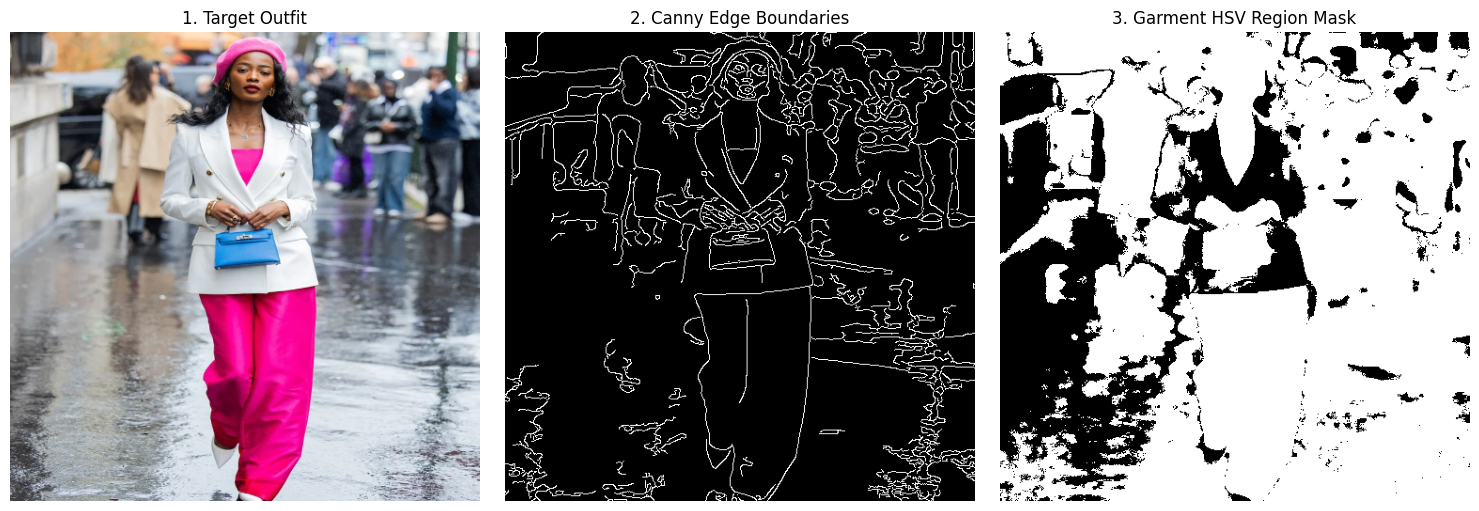

Cell 3 Complete: Extracted Target Outfit Mean HSV -> Hue: 95.5, Sat: 73.1, Val: 169.4


In [ ]:
import matplotlib.pyplot as plt

def extract_features(image):
    # Canny Edge Detection
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, threshold1=50, threshold2=150)

    # HSV Color Space Conversion
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Mask out light background
    mask = cv2.inRange(hsv, np.array([0, 15, 20]), np.array([179, 255, 255]))

    # Extract mean HSV vector
    mean_hsv = cv2.mean(hsv, mask=mask)[:3]
    return edges, mask, mean_hsv

edges, mask, target_hsv = extract_features(median_img)

# Display Canny Edges & Segmentation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(orig_img)
axes[0].set_title("1. Target Outfit")
axes[0].axis("off")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("2. Canny Edge Boundaries")
axes[1].axis("off")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title("3. Garment HSV Region Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print(f"Cell 3 Complete: Extracted Target Outfit Mean HSV -> Hue: {target_hsv[0]:.1f}, Sat: {target_hsv[1]:.1f}, Val: {target_hsv[2]:.1f}")

Recommendation Engine & Evaluation

In [ ]:
def generate_harmony_rules(hsv_vector):
    hue, sat, val = hsv_vector
    suggestions = []

    if sat < 50:
        suggestions.append("💡 Neutral Tone Detected: Consider pairing with a vibrant accessory or dark outer layer to add pop.")
    else:
        suggestions.append("✅ Rich Palette: Good color saturation detected across the garment regions.")

    if val > 200:
        suggestions.append("💡 High Lightness: Layer with a darker jacket to ground the overall outfit.")

    return suggestions

recommendations = generate_harmony_rules(target_hsv)

print("="*60)
print("   CELL 4: COLOR HARMONY & STYLE RECOMMENDATION RULES")
print("="*60)
for rec in recommendations:
    print(rec)
print("="*60)

   CELL 4: COLOR HARMONY & STYLE RECOMMENDATION RULES
✅ Rich Palette: Good color saturation detected across the garment regions.


Target vs. Personal Closet Matcher

In [ ]:
def calculate_color_match(hsv1, hsv2):
    hue_diff = abs(hsv1[0] - hsv2[0])
    if hue_diff > 90:
        hue_diff = 180 - hue_diff
    return max(0, 100 - (hue_diff / 90.0) * 100)

def match_user_closet_to_target(target_hsv, closet_items):
    print("="*65)
    print("    CELL 5: OUTFIT RECREATION & PERSONAL CLOSET MATCHING ENGINE")
    print("="*65)

    results = []
    for item_name, item_img in closet_items.items():
        _, _, item_hsv = extract_features(cv2.resize(item_img, (500, 500)))
        match_score = calculate_color_match(target_hsv, item_hsv)
        results.append((item_name, match_score))
        print(f"👕 Item: '{item_name}' ➔ Match Score: {match_score:.1f}%")

    results.sort(key=lambda x: x[1], reverse=True)
    best_item, best_score = results[0]

    print("\n" + "-"*65)
    print(f"🏆 BEST CLOSET MATCH: '{best_item}' ({best_score:.1f}% Similarity)")

    # Generate system recommendation
    print("\n💡 SYSTEM RECOMMENDATIONS FOR USER:")
    print(f"1. To recreate 'full outfit.webp', start with your '{best_item}' as the core matching piece.")
    print("2. Outfit Building Tip: Combine your shirt and jeans, then add your 'jacket.jpg' to recreate the layered look!")
    print("="*65)

# Run outfit recreation engine using your actual closet images loaded in Cell 1
closet_dict = {
    'shirt.webp': user_shirt,
    'jeans.webp': user_jeans,
    'jacket.jpg': user_jacket
}

match_user_closet_to_target(target_hsv, closet_dict)

    CELL 5: OUTFIT RECREATION & PERSONAL CLOSET MATCHING ENGINE
👕 Item: 'shirt.webp' ➔ Match Score: 97.5%
👕 Item: 'jeans.webp' ➔ Match Score: 90.4%
👕 Item: 'jacket.jpg' ➔ Match Score: 21.4%

-----------------------------------------------------------------
🏆 BEST CLOSET MATCH: 'shirt.webp' (97.5% Similarity)

💡 SYSTEM RECOMMENDATIONS FOR USER:
1. To recreate 'full outfit.webp', start with your 'shirt.webp' as the core matching piece.
2. Outfit Building Tip: Combine your shirt and jeans, then add your 'jacket.jpg' to recreate the layered look!


Filtering & Preprocessing: Gaussian Blur, Median Blur, and PSNR calculations (Lectures 1–4).Edge & Boundary Extraction: Canny Edge Detection, Sobel Gradient Operators, and Contour Analysis (Lectures 5–7).Color Spaces & Thresholding: RGB to HSV / LAB conversions, Color Range Masking, and Otsu’s Adaptive Thresholding (Lectures 8–10).Distance Metrics & Pattern Rules: Hue-distance calculations, Euclidean distance ($\Delta E$), and Histogram analysis (Lectures 11–12).